# Multilingual Word Embeddings for Indian Languages
### Training and Evaluation using FastText

**Course:** Fundamentals of Vision and Language (FOVL)  
**Submitted by:** Prasun Kumar Tripathi  
**Roll Number:** M25AI2151  
**Institution:** Indian Institute of Technology Jodhpur

---

## 1. Project overview

This notebook trains a separate 300-dimensional FastText Skip-gram model for each of seven Indian languages using the IndicCorpV2-5k dataset. The trained models are evaluated on the Word Similarity Datasets for Indian Languages.

The workflow includes:
1. Dataset and benchmark preparation
2. Unicode-aware text preprocessing
3. Training seven monolingual FastText models
4. Saving benchmark embeddings, vocabulary mappings and OOV statistics
5. Evaluating cosine similarity against human scores using Spearman correlation
6. Word-pair analysis, t-SNE visualization and inference for new words

**Important:** The models are trained from scratch. The benchmark human scores are used only for evaluation, not for training.

## 2. Environment and project setup

In [1]:
# Check the available runtime
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training will run on CPU.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
# Mount Google Drive and create the project folders
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026"

FOLDERS = [
    "data/indiccorp",
    "data/benchmark",
    "models",
    "embeddings",
    "vocabulary",
    "visualizations",
    "results",
    "report"
]

for folder in FOLDERS:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026


## 3. Install and import required libraries
Run this cell in a fresh Colab runtime before continuing.

In [3]:
%pip -q install datasets huggingface_hub scipy scikit-learn matplotlib pandas tqdm gensim==4.4.0 pyarrow

import os
import shutil
import csv
import json
import re
import unicodedata
import subprocess
import numpy as np
import pandas as pd
import gensim
from gensim.models import FastText
from scipy.stats import spearmanr, rankdata
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print("Gensim version:", gensim.__version__)
print("FastText implementation:", FastText)

Gensim version: 4.4.0
FastText implementation: <class 'gensim.models.fasttext.FastText'>


## 4. Download and inspect IndicCorpV2
The required dataset is `rony000013/indiccorpV2-5k`. This notebook uses its `data.parquet` file.

In [4]:
from huggingface_hub import HfApi, hf_hub_download

DATASET_ID = "rony000013/indiccorpV2-5k"

api = HfApi()
dataset_info = api.dataset_info(DATASET_ID)
print("Dataset:", dataset_info.id)

PARQUET_PATH = hf_hub_download(
    repo_id=DATASET_ID,
    filename="data.parquet",
    repo_type="dataset"
)

df = pd.read_parquet(PARQUET_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset: rony000013/indiccorpV2-5k


data.parquet: reconstructing file:   0%|          |  0.00B / 28.8MB            

data.parquet: downloading bytes:           |  0.00B            

Dataset shape: (118243, 3)
Columns: ['language', 'code', 'text']


,language,code,text
0,Assamese,as,ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে ...
1,Assamese,as,ৰাণু মণ্ডলৰ সুৱদী কন্ঠত মুগ্ধ হৈ ভাইজান ছলমানে...
2,Assamese,as,ইফালে আজিৰ মেচখন সম্পৰ্কে নৰ্থ-ইষ্টৰ প্ৰশিক্ষক...
3,Assamese,as,মোহন ভাৱৰীয়াই তেওঁৰ প্ৰাথমিক শিক্ষা কৈহাটীৰ ২...
4,Assamese,as,>> 02015/02016 মুম্বাই-পুনে-মুম্বাই বিশেষ ৰে’ল...


In [5]:
TARGET_LANGUAGES = [
    "Hindi", "Gujarati", "Marathi", "Punjabi",
    "Tamil", "Telugu", "Urdu"
]

print("Records available for each target language:")
for lang in TARGET_LANGUAGES:
    count = (df["language"].str.lower() == lang.lower()).sum()
    print(f"{lang}: {count:,}")

Records available for each target language:
Hindi: 5,000
Gujarati: 5,000
Marathi: 5,000
Punjabi: 5,000
Tamil: 5,000
Telugu: 5,000
Urdu: 5,000


## 5. Download the word-similarity benchmark
The benchmark repository contains one word-similarity file for each target language.

In [6]:
BENCHMARK_DIR = os.path.join(PROJECT_DIR, "data", "benchmark")
REPO_URL = (
    "https://github.com/syedsarfarazakhtar/"
    "Word-Similarity-Datasets-for-Indian-Languages.git"
)

if not os.path.exists(os.path.join(BENCHMARK_DIR, ".git")):
    # Clone into a temporary folder first to avoid conflicts with existing files.
    temp_clone = os.path.join(PROJECT_DIR, "data", "benchmark_download")
    if os.path.exists(temp_clone):
        shutil.rmtree(temp_clone)
    result = subprocess.run(
        ["git", "clone", REPO_URL, temp_clone],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
    os.makedirs(BENCHMARK_DIR, exist_ok=True)
    for item in os.listdir(temp_clone):
        src = os.path.join(temp_clone, item)
        dst = os.path.join(BENCHMARK_DIR, item)
        if not os.path.exists(dst):
            shutil.move(src, dst)
    shutil.rmtree(temp_clone)

print("Benchmark files:")
for lang in TARGET_LANGUAGES:
    path = os.path.join(BENCHMARK_DIR, f"{lang}-WS.txt")
    print(lang, "->", "FOUND" if os.path.exists(path) else "MISSING")

Benchmark files:
Hindi -> FOUND
Gujarati -> FOUND
Marathi -> FOUND
Punjabi -> FOUND
Tamil -> FOUND
Telugu -> FOUND
Urdu -> FOUND


## 6. Text preprocessing and benchmark loading

Text is normalized using Unicode NFC. The tokenizer retains Unicode letters and combining marks so that characters from the selected Indic scripts are preserved. Empty or very short records are excluded.

The benchmark files use different delimiters: Hindi is comma-separated, while the other language files are tab-separated. The parser removes empty trailing fields but preserves the original word-pair order.

In [7]:
def tokenize_indic(text):
    text = unicodedata.normalize("NFC", str(text))
    tokens = []
    current = []

    for char in text:
        category = unicodedata.category(char)
        if category.startswith(("L", "M")):
            current.append(char)
        else:
            if current:
                tokens.append("".join(current))
                current = []

    if current:
        tokens.append("".join(current))

    return tokens


# Collect source text for each language
training_data = {}
for lang in TARGET_LANGUAGES:
    subset = df[df["language"].str.lower() == lang.lower()]
    training_data[lang] = subset["text"].dropna().astype(str).tolist()

# Tokenize the corpora
tokenized_corpora = {}
for lang, texts in training_data.items():
    sentences = [
        tokens for text in texts
        if len(tokens := tokenize_indic(text)) >= 2
    ]
    tokenized_corpora[lang] = sentences

    token_count = sum(len(sentence) for sentence in sentences)
    print(f"{lang}: {len(sentences):,} sentences | {token_count:,} tokens")


# Load benchmark pairs
benchmark_data = {}

for lang in TARGET_LANGUAGES:
    filepath = os.path.join(BENCHMARK_DIR, f"{lang}-WS.txt")
    if not os.path.exists(filepath):
        raise FileNotFoundError(filepath)

    delimiter = "," if lang == "Hindi" else "\t"
    rows = []

    with open(filepath, "r", encoding="utf-8-sig", newline="") as f:
        reader = csv.reader(f, delimiter=delimiter)
        for row in reader:
            # Remove blank fields, including trailing empty columns.
            row = [field.strip() for field in row if field.strip()]
            if len(row) < 3:
                continue
            try:
                score = float(row[2])
                rows.append((row[0], row[1], score))
            except ValueError:
                # Skip header or malformed rows.
                continue

    benchmark_data[lang] = pd.DataFrame(
        rows, columns=["word1", "word2", "human_score"]
    )
    print(f"{lang}: {len(benchmark_data[lang]):,} benchmark pairs")

print("Total benchmark pairs:",
      sum(len(benchmark_data[lang]) for lang in TARGET_LANGUAGES))

Hindi: 4,992 sentences | 282,296 tokens
Gujarati: 4,985 sentences | 202,193 tokens
Marathi: 4,978 sentences | 204,099 tokens
Punjabi: 4,979 sentences | 271,450 tokens
Tamil: 4,902 sentences | 168,257 tokens
Telugu: 4,936 sentences | 177,950 tokens
Urdu: 4,932 sentences | 358,962 tokens
Hindi: 235 benchmark pairs
Gujarati: 163 benchmark pairs
Marathi: 104 benchmark pairs
Punjabi: 143 benchmark pairs
Tamil: 96 benchmark pairs
Telugu: 111 benchmark pairs
Urdu: 100 benchmark pairs
Total benchmark pairs: 952


## 7. Train the seven FastText models

Each language has its own model. The configuration below is the one used for the final experiment. Training is from scratch on the selected IndicCorpV2 corpus.

In [8]:
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

fasttext_models = {}

for lang in TARGET_LANGUAGES:
    print(f"\nTraining FastText model: {lang}")

    model = FastText(
        sentences=tokenized_corpora[lang],
        vector_size=300,
        window=5,
        min_count=1,
        workers=2,
        sg=1,
        negative=5,
        epochs=10,
        min_n=3,
        max_n=6,
        bucket=200000,
        seed=42
    )

    model_path = os.path.join(
        MODEL_DIR, f"{lang.lower()}_fasttext.model"
    )
    model.save(model_path)
    fasttext_models[lang] = model

    print(
        f"{lang}: vocabulary={len(model.wv.key_to_index):,}; "
        f"saved to {model_path}"
    )

print("\nAll seven models have been trained and saved.")


Training FastText model: Hindi
Hindi: vocabulary=25,340; saved to /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/models/hindi_fasttext.model

Training FastText model: Gujarati
Gujarati: vocabulary=38,401; saved to /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/models/gujarati_fasttext.model

Training FastText model: Marathi
Marathi: vocabulary=44,981; saved to /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/models/marathi_fasttext.model

Training FastText model: Punjabi
Punjabi: vocabulary=26,232; saved to /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/models/punjabi_fasttext.model

Training FastText model: Tamil
Tamil: vocabulary=55,077; saved to /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/models/tamil_fasttext.model

Training FastText model: Telugu
Telugu: vocabulary=44,197; saved to /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/models/telugu_fasttext.model

Training FastText model: Urdu
Urdu: vocabular

## 8. Generate benchmark embeddings and vocabulary mappings

For every benchmark pair, both word vectors are obtained from the relevant FastText model. FastText can construct a vector for an out-of-vocabulary word using character n-grams. The original benchmark pair order is preserved.

The saved NumPy array for each language has shape `(number_of_pairs, 2, 300)`.

In [9]:
EMBEDDING_DIR = os.path.join(PROJECT_DIR, "embeddings")
VOCAB_DIR = os.path.join(PROJECT_DIR, "vocabulary")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

for folder in [EMBEDDING_DIR, VOCAB_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

oov_statistics = {}

for lang in TARGET_LANGUAGES:
    model = fasttext_models[lang]
    benchmark = benchmark_data[lang]

    pair_vectors = []
    total_words = 0
    oov_words = 0

    for _, row in benchmark.iterrows():
        vectors_for_pair = []

        for word in [row["word1"], row["word2"]]:
            word = unicodedata.normalize("NFC", str(word).strip())
            total_words += 1

            if word not in model.wv.key_to_index:
                oov_words += 1

            vectors_for_pair.append(model.wv[word])

        pair_vectors.append(vectors_for_pair)

    vectors = np.asarray(pair_vectors, dtype=np.float32)

    np.save(
        os.path.join(EMBEDDING_DIR, f"{lang.lower()}_embeddings.npy"),
        vectors
    )

    with open(
        os.path.join(VOCAB_DIR, f"{lang.lower()}_vocabulary.json"),
        "w", encoding="utf-8"
    ) as f:
        json.dump(model.wv.key_to_index, f, ensure_ascii=False)

    oov_statistics[lang] = {
        "total_words": total_words,
        "oov_words": oov_words,
        "oov_percentage": round(100 * oov_words / total_words, 2),
        "pairs": len(benchmark),
        "embedding_shape": list(vectors.shape)
    }

    print(
        f"{lang}: shape={vectors.shape}; "
        f"OOV={oov_words}/{total_words} "
        f"({oov_statistics[lang]['oov_percentage']}%)"
    )

with open(
    os.path.join(RESULTS_DIR, "oov_statistics.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(oov_statistics, f, indent=4, ensure_ascii=False)

print("Embeddings, vocabulary mappings and OOV statistics saved.")

Hindi: shape=(235, 2, 300); OOV=62/470 (13.19%)
Gujarati: shape=(163, 2, 300); OOV=28/326 (8.59%)
Marathi: shape=(104, 2, 300); OOV=28/208 (13.46%)
Punjabi: shape=(143, 2, 300); OOV=28/286 (9.79%)
Tamil: shape=(96, 2, 300); OOV=27/192 (14.06%)
Telugu: shape=(111, 2, 300); OOV=57/222 (25.68%)
Urdu: shape=(100, 2, 300); OOV=27/200 (13.5%)
Embeddings, vocabulary mappings and OOV statistics saved.


## 9. Evaluate embeddings using cosine similarity and Spearman correlation

In [10]:
evaluation_results = []

for lang in TARGET_LANGUAGES:
    benchmark = benchmark_data[lang]
    vectors = np.load(
        os.path.join(EMBEDDING_DIR, f"{lang.lower()}_embeddings.npy")
    )

    human_scores = benchmark["human_score"].to_numpy(dtype=float)
    model_scores = []

    for pair in vectors:
        score = cosine_similarity(
            pair[0].reshape(1, -1),
            pair[1].reshape(1, -1)
        )[0, 0]
        model_scores.append(float(score))

    model_scores = np.asarray(model_scores)
    correlation, p_value = spearmanr(human_scores, model_scores)

    evaluation_results.append({
        "Language": lang,
        "Pairs": len(benchmark),
        "Spearman_Correlation": correlation,
        "P_Value": p_value,
        "Mean_Cosine_Similarity": float(np.mean(model_scores))
    })

results_df = pd.DataFrame(evaluation_results)
macro_average = results_df["Spearman_Correlation"].mean()

display(results_df)
print(f"Macro-average Spearman correlation: {macro_average:.4f}")

results_df.to_csv(
    os.path.join(RESULTS_DIR, "evaluation_results.csv"),
    index=False
)
print("Evaluation results saved.")

,Language,Pairs,Spearman_Correlation,P_Value,Mean_Cosine_Similarity
0,Hindi,235,0.184512,0.004542,0.740053
1,Gujarati,163,0.256094,0.000968,0.824392
2,Marathi,104,0.125561,0.204072,0.852844
3,Punjabi,143,0.368131,0.000006,0.770791
4,Tamil,96,0.368008,0.000225,0.777444
5,Telugu,111,0.225227,0.017469,0.806860
6,Urdu,100,0.207950,0.037884,0.718007


Macro-average Spearman correlation: 0.2479
Evaluation results saved.


## 10. Word-pair analysis

This step compares the relative ranking of human similarity scores and model cosine similarities within each language. It selects four examples with the smallest rank differences and four with the largest rank differences across the combined results.

In [11]:
analysis_rows = []

for lang in TARGET_LANGUAGES:
    benchmark = benchmark_data[lang].copy()
    model = fasttext_models[lang]

    human_scores = benchmark["human_score"].to_numpy(dtype=float)
    model_scores = []

    for word1, word2 in zip(benchmark["word1"], benchmark["word2"]):
        vec1 = model.wv[unicodedata.normalize("NFC", str(word1).strip())]
        vec2 = model.wv[unicodedata.normalize("NFC", str(word2).strip())]

        denom = np.linalg.norm(vec1) * np.linalg.norm(vec2)
        similarity = 0.0 if denom == 0 else float(np.dot(vec1, vec2) / denom)
        model_scores.append(similarity)

    model_scores = np.asarray(model_scores)
    human_ranks = rankdata(human_scores, method="average") / len(human_scores)
    model_ranks = rankdata(model_scores, method="average") / len(model_scores)
    rank_difference = np.abs(human_ranks - model_ranks)

    for i in range(len(benchmark)):
        analysis_rows.append({
            "Language": lang,
            "Word 1": benchmark.iloc[i]["word1"],
            "Word 2": benchmark.iloc[i]["word2"],
            "Human Score": human_scores[i],
            "Model Cosine": model_scores[i],
            "Rank Difference": rank_difference[i]
        })

analysis_df = pd.DataFrame(analysis_rows)
close_examples = analysis_df.nsmallest(4, "Rank Difference").copy()
close_examples["Analysis"] = "Closely aligned"
poor_examples = analysis_df.nlargest(4, "Rank Difference").copy()
poor_examples["Analysis"] = "Poorly aligned"

selected_examples = pd.concat(
    [close_examples, poor_examples], ignore_index=True
)

selected_examples.to_csv(
    os.path.join(RESULTS_DIR, "word_pair_analysis.csv"),
    index=False
)

display(selected_examples.round(4))
print("Eight examples saved.")

,Language,Word 1,Word 2,Human Score,Model Cosine,Rank Difference,Analysis
0,Gujarati,વાઘ,વાઘ,10.000,1.0000,0.0000,Closely aligned
1,Gujarati,સમાચાર,અહેવાલ,7.000,0.8181,0.0000,Closely aligned
2,Marathi,वाघ,वाघ,10.000,1.0000,0.0000,Closely aligned
3,Tamil,ராஜா,ராணி,8.625,0.9475,0.0000,Closely aligned
4,Gujarati,વિલંબ,જાતિવાદ,0.000,0.9728,0.9417,Poorly aligned
5,Telugu,మైనారిటీ,శాంతి,1.000,0.9600,0.9144,Poorly aligned
6,Hindi,पैसे,धन,9.200,0.5631,0.9106,Poorly aligned
7,Marathi,चित्रपट,समीक्षक,8.500,0.5612,0.8894,Poorly aligned


Eight examples saved.


## 11. t-SNE visualization

The following plots reduce the 300-dimensional vectors of 100 frequent vocabulary words to two dimensions. The plots are exploratory visualizations; they are not a direct measure of embedding quality.

Noto fonts are installed so that the language scripts can be displayed. Urdu labels are reshaped for right-to-left display.

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fonts-noto-mono.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../fonts-noto-mono_20201225-2_all.deb ...
Unpacking fonts-noto-mono (20201225-2) ...
Selecting previously unselected package fonts-noto-core.
Preparing to unpack .../fonts-noto-core_20201225-2_all.deb ...
Unpacking fonts-noto-core (20201225-2) ...
Selecting previously unselected package fonts-noto-extra.
Preparing to unpack .../fonts-noto-extra_20201225-2_all.deb ...
Unpacking fonts-noto-extra (20201225-2) ...
Selecting previously unselected package fonts-noto-unhinted.
Preparing to unpack .../fonts-noto-unhinted_20201225-2_all.deb ...
Unpacking fonts-noto-unhinted (20201225-2) ...
Setting up fonts-noto-mono (20201225-2) ...
Setting up fonts-noto-extra

/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)


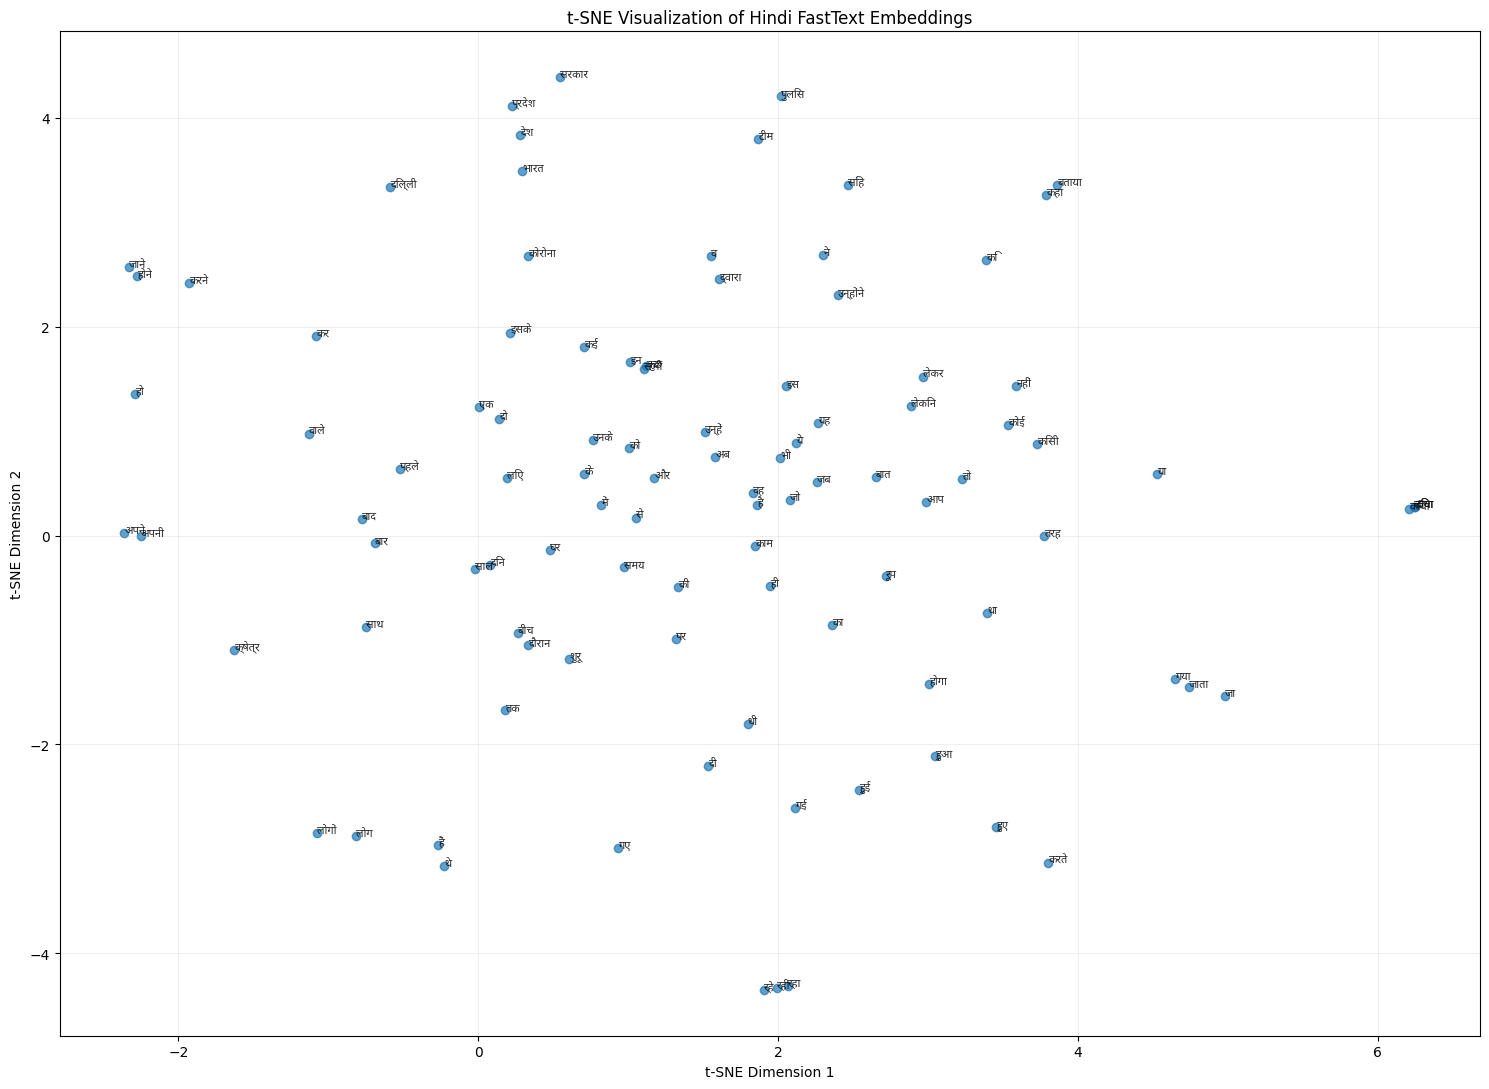

Hindi: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/hindi_tsne.png


/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gujarati.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gujarati.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gujarati.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gujarati.
  fig.canvas.print_figure(bytes_io, **kw)


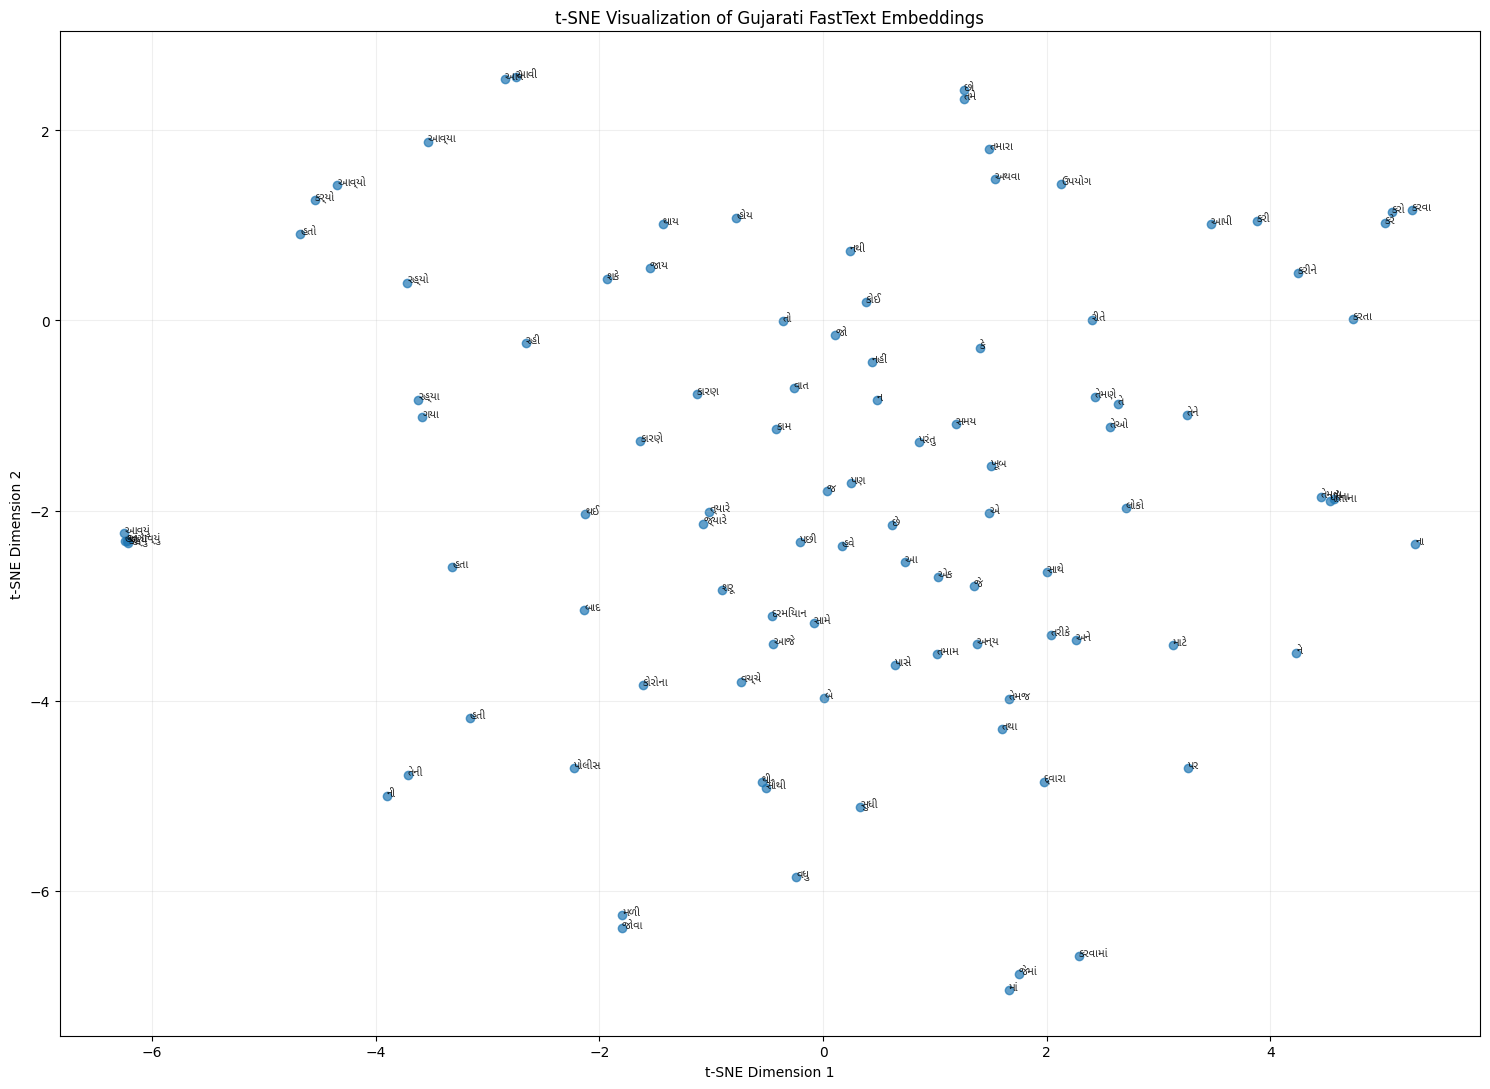

Gujarati: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/gujarati_tsne.png


/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)


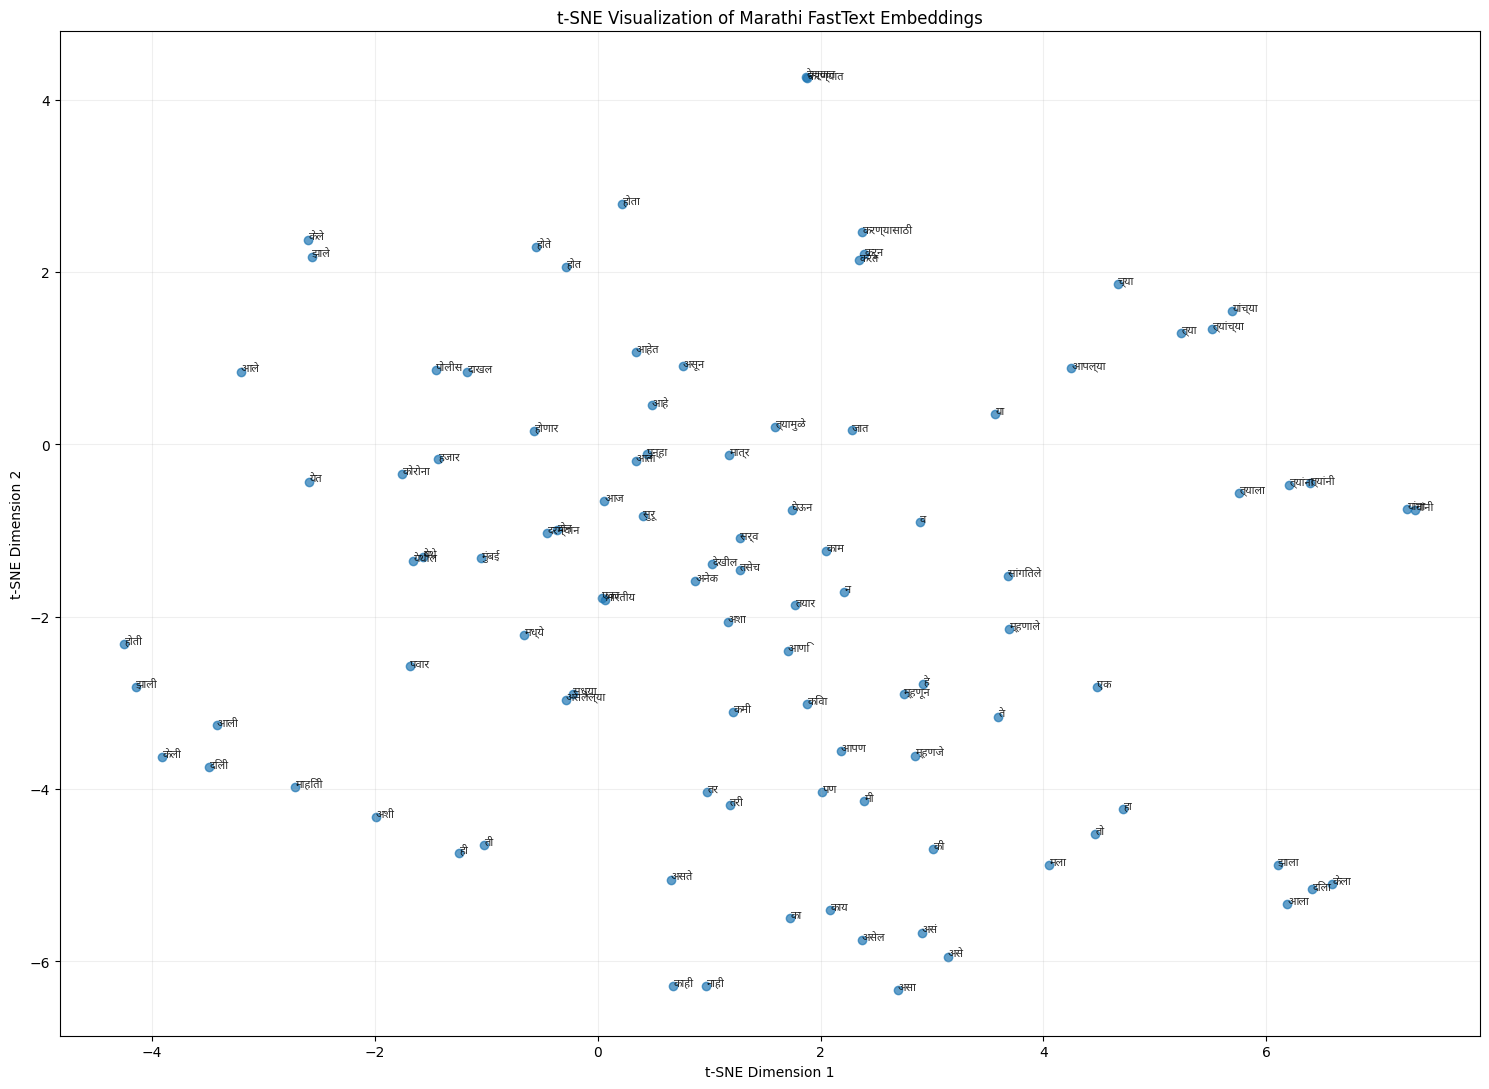

Marathi: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/marathi_tsne.png


/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gurmukhi.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gurmukhi.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gurmukhi.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Gurmukhi.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Gurmukhi.
  fig.canvas.print_figure(bytes_io, **kw)


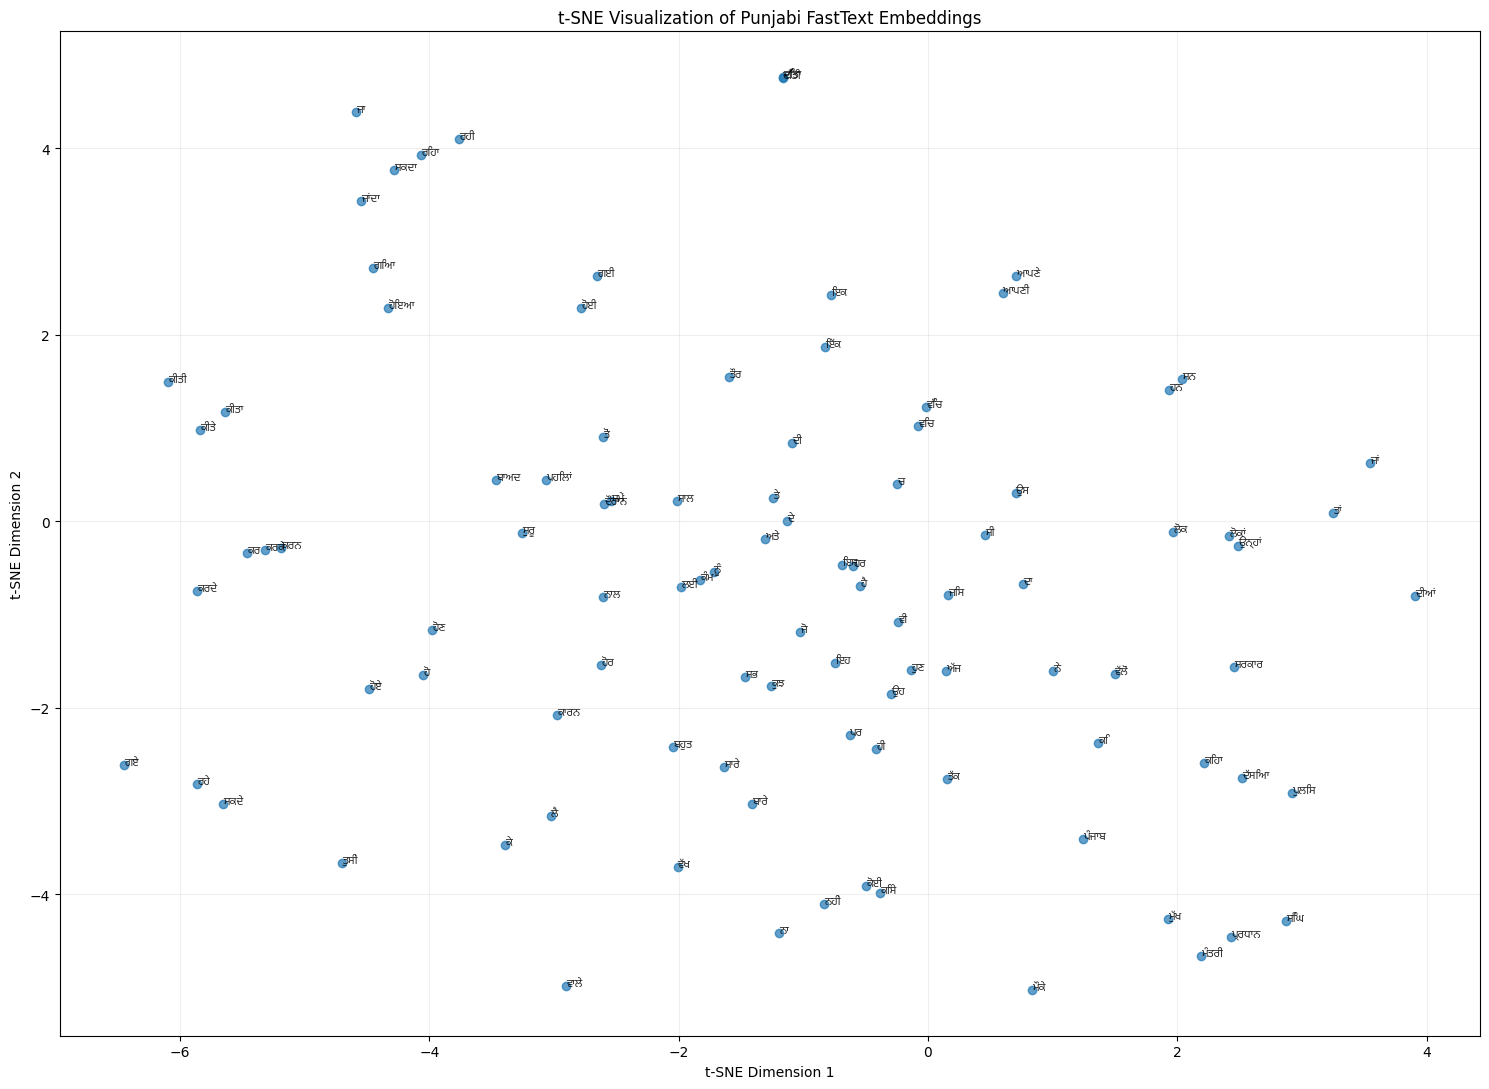

Punjabi: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/punjabi_tsne.png


/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Tamil.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Tamil.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Tamil.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Tamil.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Tamil.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Tamil.
  fig.canvas.print_figure(bytes_io, **kw)


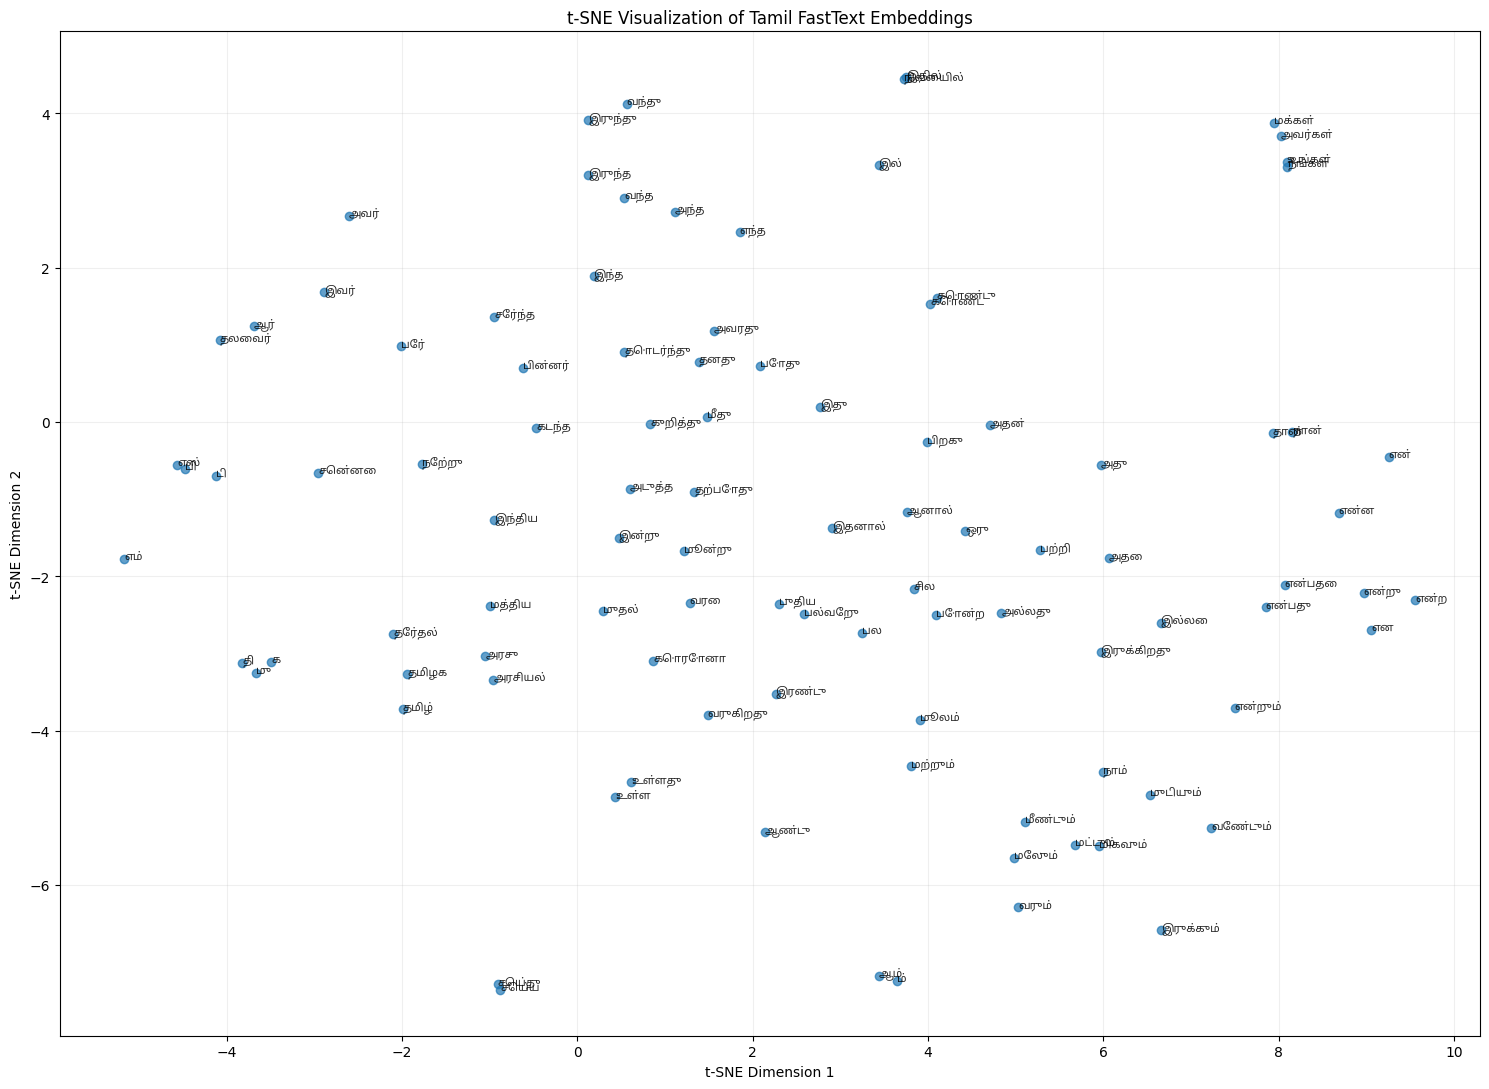

Tamil: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/tamil_tsne.png


/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Telugu.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Telugu.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Telugu.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Telugu.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Telugu.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Telugu.
  fig.canvas.print_figure(bytes_io, **kw)


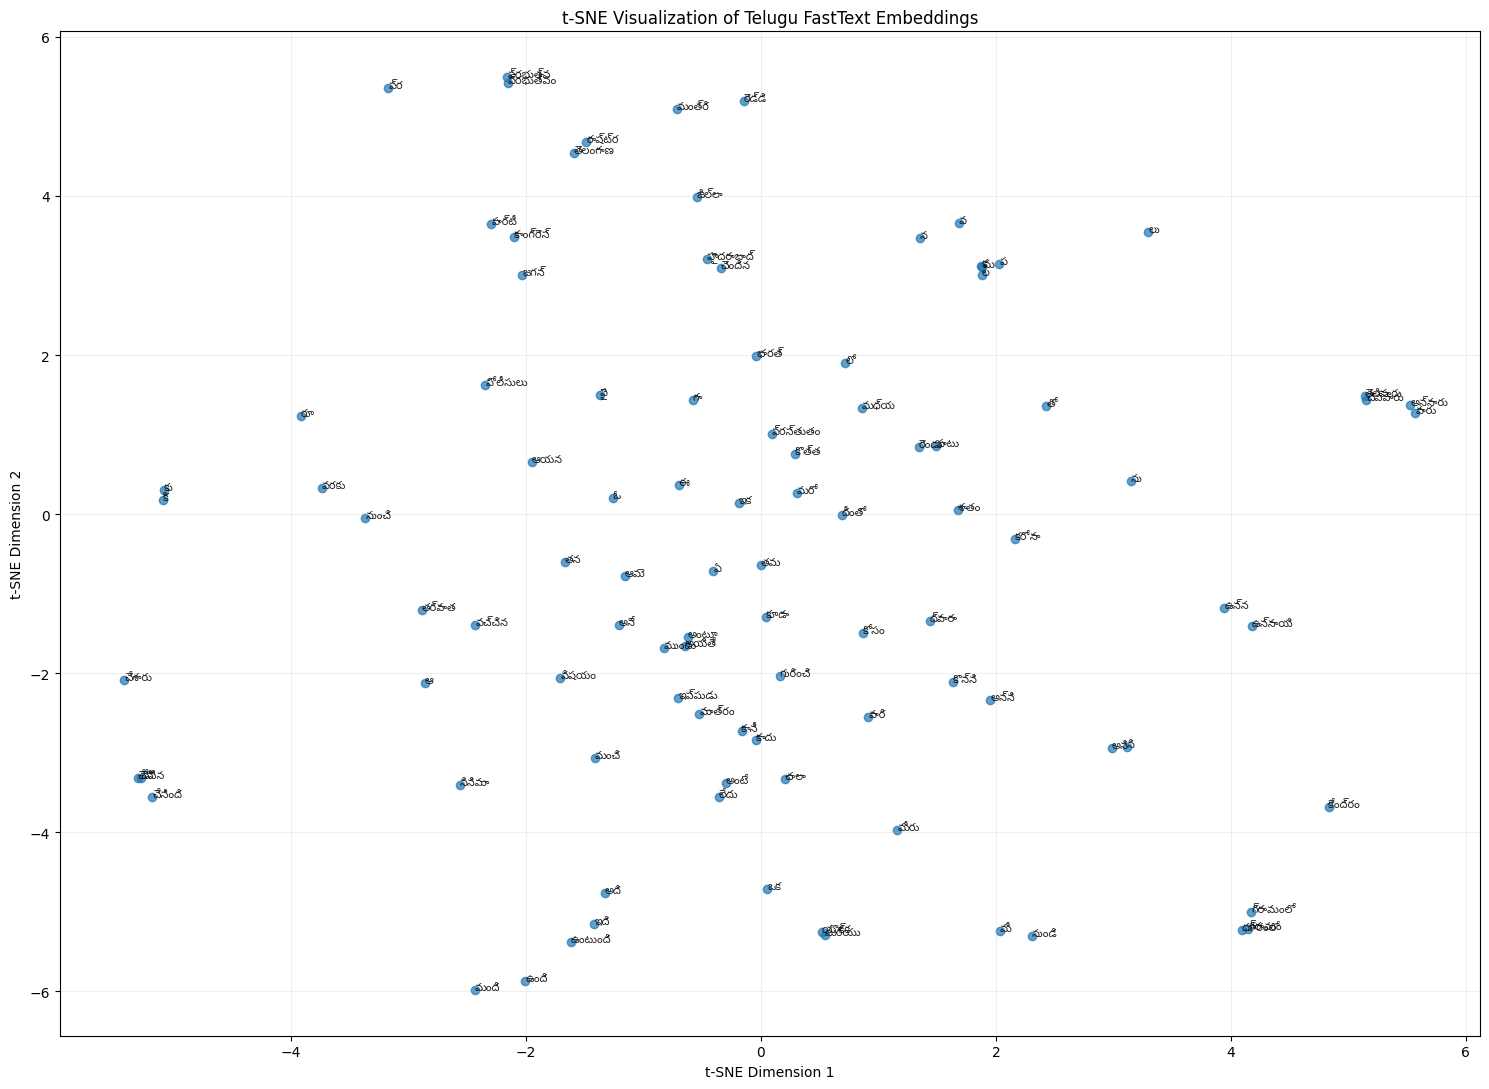

Telugu: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/telugu_tsne.png


/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:53: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Arabic.
  plt.tight_layout()
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/tmp/ipykernel_1339/2381832221.py:56: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Arabic.
  plt.savefig(save_path, dpi=300, bbox_inches="tight")
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Arabic.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Arabic.
  fig.canvas.print_figure(bytes_io, **kw)


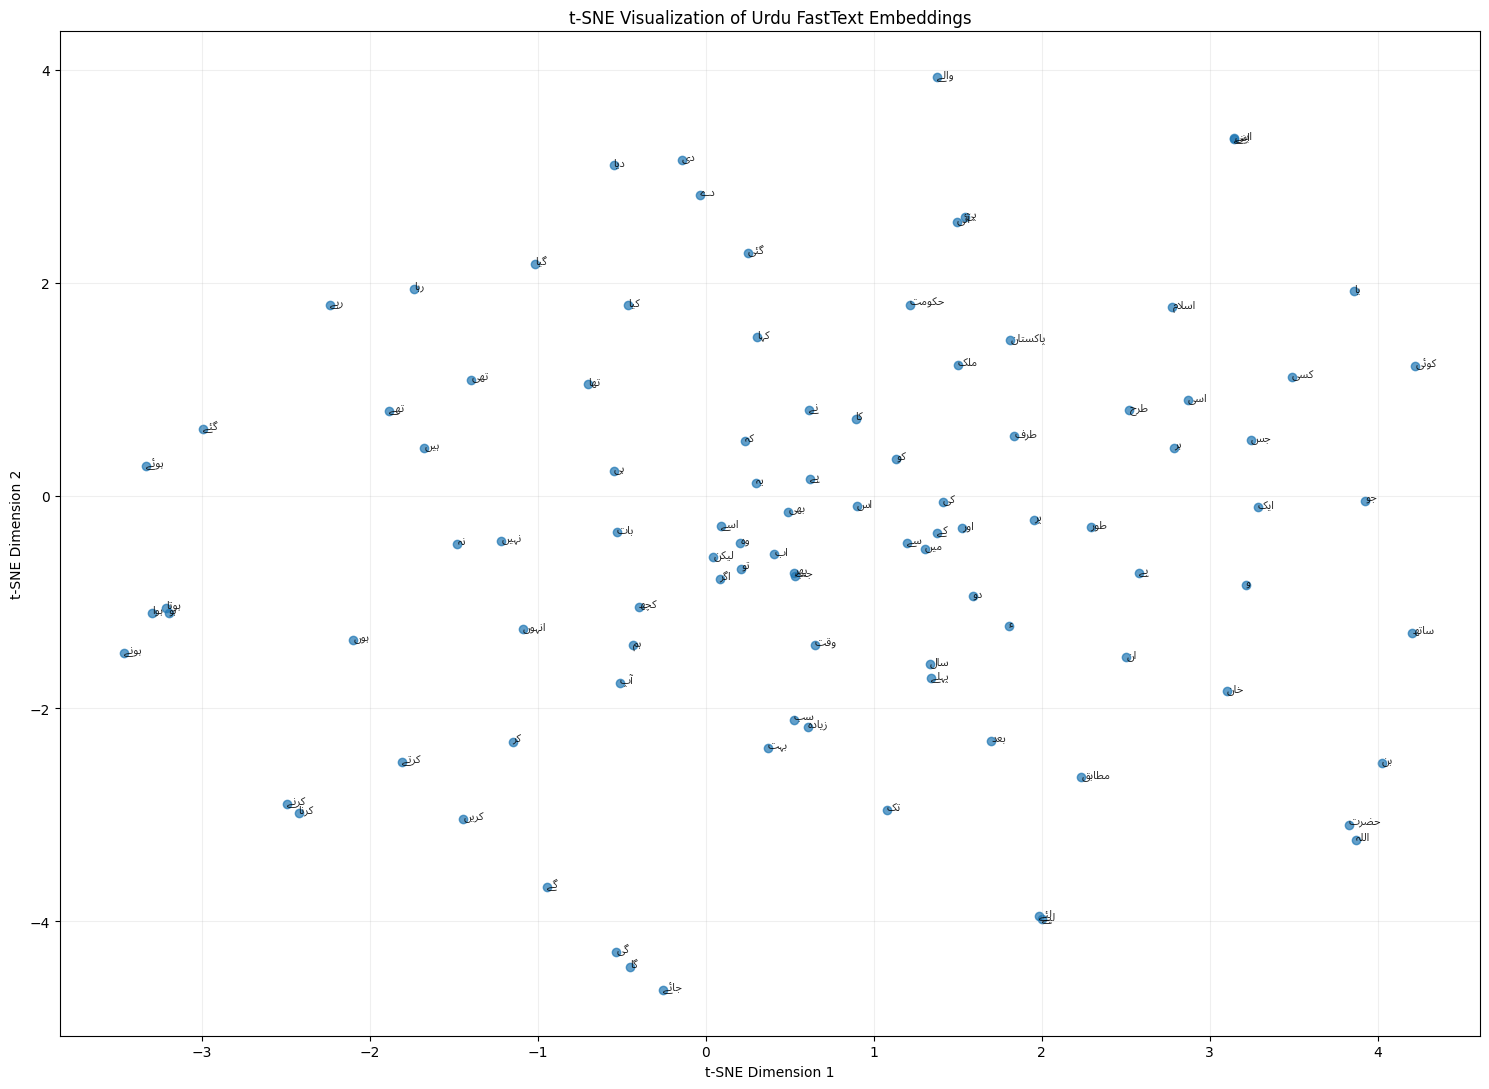

Urdu: saved -> /content/drive/MyDrive/Colab Notebooks/FOVL_Assignment_2026/visualizations/urdu_tsne.png
All seven t-SNE plots saved.


In [12]:
!apt-get -qq update
!apt-get -qq install -y fonts-noto-core fonts-noto-extra fonts-noto-unhinted
%pip -q install arabic-reshaper python-bidi

import matplotlib.font_manager as fm
import arabic_reshaper
from bidi.algorithm import get_display

font_paths = {
    "Hindi": "/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf",
    "Gujarati": "/usr/share/fonts/truetype/noto/NotoSansGujarati-Regular.ttf",
    "Marathi": "/usr/share/fonts/truetype/noto/NotoSansDevanagari-Regular.ttf",
    "Punjabi": "/usr/share/fonts/truetype/noto/NotoSansGurmukhi-Regular.ttf",
    "Tamil": "/usr/share/fonts/truetype/noto/NotoSansTamil-Regular.ttf",
    "Telugu": "/usr/share/fonts/truetype/noto/NotoSansTelugu-Regular.ttf",
    "Urdu": "/usr/share/fonts/truetype/noto/NotoSansArabic-Regular.ttf"
}

VIS_DIR = os.path.join(PROJECT_DIR, "visualizations")
os.makedirs(VIS_DIR, exist_ok=True)

for lang in TARGET_LANGUAGES:
    model = fasttext_models[lang]
    words = list(model.wv.key_to_index.keys())[:100]
    vectors = np.array([model.wv[word] for word in words])

    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )
    coordinates = tsne.fit_transform(vectors)

    font = fm.FontProperties(fname=font_paths[lang])
    plt.figure(figsize=(15, 11))
    plt.scatter(coordinates[:, 0], coordinates[:, 1], alpha=0.7)

    for i, word in enumerate(words):
        label = word
        if lang == "Urdu":
            label = get_display(arabic_reshaper.reshape(word))
        plt.annotate(
            label, (coordinates[i, 0], coordinates[i, 1]),
            fontproperties=font, fontsize=8, alpha=0.85
        )

    plt.title(f"t-SNE Visualization of {lang} FastText Embeddings")
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.grid(alpha=0.2)
    plt.tight_layout()

    save_path = os.path.join(VIS_DIR, f"{lang.lower()}_tsne.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"{lang}: saved -> {save_path}")

print("All seven t-SNE plots saved.")

## 12. Load saved models and generate embeddings for new words

This section demonstrates how to load the saved FastText models and obtain a 300-dimensional vector for an input word. The function also reports whether the word is in the model's explicit vocabulary. FastText can still produce a vector for many OOV words through subword information.

In [13]:
loaded_models = {}

for lang in TARGET_LANGUAGES:
    model_path = os.path.join(
        MODEL_DIR, f"{lang.lower()}_fasttext.model"
    )
    loaded_models[lang] = FastText.load(model_path)
    print(f"{lang}: model loaded")


def get_word_embedding(language, word):
    if language not in loaded_models:
        raise ValueError(f"Unsupported language: {language}")

    word = unicodedata.normalize("NFC", str(word).strip())
    if not word:
        raise ValueError("Input word cannot be empty.")

    model = loaded_models[language]
    is_oov = word not in model.wv.key_to_index
    vector = model.wv[word]

    return vector, is_oov


# Demonstrate an in-vocabulary word and a constructed OOV test word
sample_language = "Hindi"
sample_word = next(iter(loaded_models[sample_language].wv.key_to_index))

for test_word in [sample_word, sample_word + "xyz"]:
    vector, is_oov = get_word_embedding(sample_language, test_word)
    print(
        f"Word: {test_word} | "
        f"Status: {'OOV' if is_oov else 'In vocabulary'} | "
        f"Shape: {vector.shape} | "
        f"Finite: {np.isfinite(vector).all()}"
    )

Hindi: model loaded
Gujarati: model loaded
Marathi: model loaded
Punjabi: model loaded
Tamil: model loaded
Telugu: model loaded
Urdu: model loaded
Word: के | Status: In vocabulary | Shape: (300,) | Finite: True
Word: केxyz | Status: OOV | Shape: (300,) | Finite: True


## 13. Final file checks

This cell checks that all seven embedding arrays exist, have the expected dimensions and contain finite values. It also checks that the saved model files and output folders are present.

In [14]:
expected_pairs = {
    "Hindi": 235, "Gujarati": 163, "Marathi": 104,
    "Punjabi": 143, "Tamil": 96, "Telugu": 111, "Urdu": 100
}

print("EMBEDDING VALIDATION")
for lang, count in expected_pairs.items():
    path = os.path.join(EMBEDDING_DIR, f"{lang.lower()}_embeddings.npy")
    arr = np.load(path)
    valid = arr.shape == (count, 2, 300) and np.isfinite(arr).all()
    print(f"{lang}: {arr.shape} | {'PASS' if valid else 'CHECK'}")

print("\nMODEL FILES")
for lang in TARGET_LANGUAGES:
    path = os.path.join(MODEL_DIR, f"{lang.lower()}_fasttext.model")
    print(f"{lang}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

print("\nRESULT FILES")
for filename in [
    "evaluation_results.csv",
    "oov_statistics.json",
    "word_pair_analysis.csv"
]:
    path = os.path.join(RESULTS_DIR, filename)
    print(f"{filename}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

print("\nNotebook workflow completed.")

EMBEDDING VALIDATION
Hindi: (235, 2, 300) | PASS
Gujarati: (163, 2, 300) | PASS
Marathi: (104, 2, 300) | PASS
Punjabi: (143, 2, 300) | PASS
Tamil: (96, 2, 300) | PASS
Telugu: (111, 2, 300) | PASS
Urdu: (100, 2, 300) | PASS

MODEL FILES
Hindi: FOUND
Gujarati: FOUND
Marathi: FOUND
Punjabi: FOUND
Tamil: FOUND
Telugu: FOUND
Urdu: FOUND

RESULT FILES
evaluation_results.csv: FOUND
oov_statistics.json: FOUND
word_pair_analysis.csv: FOUND

Notebook workflow completed.
